In [2]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import tensorflow as tf
random.seed(42)
tf.random.set_seed(42)
%matplotlib inline

In [30]:
df=pd.read_csv('data/communes-france-2026.csv',sep=None, engine='python')
print(df.head())


  code_insee             nom_standard        nom_sans_pronom  \
0      01001  L'Abergement-Clémenciat  Abergement-Clémenciat   
1      01002    L'Abergement-de-Varey    Abergement-de-Varey   
2      01004        Ambérieu-en-Bugey      Ambérieu-en-Bugey   
3      01005      Ambérieux-en-Dombes    Ambérieux-en-Dombes   
4      01006                  Ambléon                Ambléon   

                       nom_a                      nom_de  \
0  à l'Abergement-Clémenciat  de l'Abergement-Clémenciat   
1    à l'Abergement-de-Varey    de l'Abergement-de-Varey   
2        à Ambérieu-en-Bugey         d'Ambérieu-en-Bugey   
3      à Ambérieux-en-Dombes       d'Ambérieux-en-Dombes   
4                  à Ambléon                   d'Ambléon   

           nom_sans_accent   nom_standard_majuscule typecom typecom_texte  \
0  l-abergement-clemenciat  L'ABERGEMENT-CLÉMENCIAT     COM       commune   
1    l-abergement-de-varey    L'ABERGEMENT-DE-VAREY     COM       commune   
2        amberieu-en-bu

In [31]:
# Accents rares remplacés par la lettre simple (ajuste selon tes comptages)
REMPLACEMENTS = {
    'ë': 'e', 'ï': 'i', 'ü': 'u', 'û': 'u',
}

def nettoyer(nom):
    """Renvoie une liste de noms propres (0, 1 ou plusieurs) à partir d'un libellé brut."""
    if not isinstance(nom, str):           # case vide (NaN) → on ignore
        return []
    nom = nom.lower()                      # 1. tout en minuscules
    nom = nom.split('(')[0]                # 2. on coupe tout ce qui suit une parenthèse
    morceaux = nom.split('/')              # 3. "A / B" → deux noms séparés
    resultats = []
    for m in morceaux:
        rejeter = False
        for ch in m:
            if ch.isdigit() or ch == '°':
                rejeter = True
        if rejeter:
            continue
        nouveau = ''
        for ch in m:
            if ch in REMPLACEMENTS:
                nouveau += REMPLACEMENTS[ch]
            else:
                nouveau += ch
        m = nouveau
        m = ' '.join(m.split())
        if len(m) >= 2:
            resultats.append(m)
    return resultats
words = []
for libelle in df["nom_sans_pronom"]:
    for propre in nettoyer(libelle):       # nettoyer peut renvoyer 0, 1 ou plusieurs noms
        words.append(propre)

words = sorted(set(words))                   # dédoublonnage
print(len(words), 'noms')

chars = sorted(set(''.join(words)))
print(len(chars), repr(''.join(chars)))
assert '.' not in chars                    # '.' doit rester libre pour le token de fin


32465 noms
39 " '-abcdefghijklmnopqrstuvwxyzàâçèéêîôÿœ"


In [32]:
chars = sorted(set(''.join(words)))
stoi = {'.': 0}                      # '.' = début / fin de mot
for i, ch in enumerate(chars):
    stoi[ch] = i + 1
itos = {i: ch for ch, i in stoi.items()}
vocab_size = len(itos)
print(vocab_size)

40


In [33]:
block_size=3
def build_dataset(words):
    X, Y = [], []
    for w in words:
    #print(w)
        context = [0] * block_size
        for ch in w + '.':
          ix = stoi[ch]
          X.append(context)
          Y.append(ix)
          context = context[1:] + [ix] # crop and append

    X = np.array(X, dtype=np.int32)
    Y = np.array(Y, dtype=np.int32)
    print(X.shape, Y.shape)
    print(X.shape, Y.shape)
    return X, Y
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

(332698, 3) (332698,)
(332698, 3) (332698,)
(41543, 3) (41543,)
(41543, 3) (41543,)
(41292, 3) (41292,)
(41292, 3) (41292,)


In [34]:
n_embd = 10
n_hidden = 200

model = tf.keras.Sequential([
    tf.keras.Input(shape=(block_size,), dtype='int32'),                 # 3 indices
    tf.keras.layers.Embedding(vocab_size, n_embd, name='embedding'),    # table C → (batch, 3, 10)
    tf.keras.layers.Flatten(),                                          # → (batch, 30)
    tf.keras.layers.Dense(n_hidden, activation='tanh'),                 # couche cachée
    tf.keras.layers.Dense(vocab_size),                                  # logits (pas de softmax)
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 10)          │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 200)            │         6,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 40)             │         8,040 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,640 (57.19 KB)

 Trainable params: 14,640 (57.19 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
)

Epoch 1/10
10397/10397 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step - loss: 2.2469 - val_loss: 2.1810
Epoch 2/10
10397/10397 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step - loss: 2.1608 - val_loss: 2.1223
Epoch 3/10
10397/10397 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step - loss: 2.0894 - val_loss: 2.0524
Epoch 4/10
10397/10397 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step - loss: 2.0240 - val_loss: 1.9997
Epoch 5/10
10397/10397 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step - loss: 1.9777 - val_loss: 1.9640
Epoch 6/10
10397/10397 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step - loss: 1.9468 - val_loss: 1.9409
Epoch 7/10
10397/10397 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step - loss: 1.9261 - val_loss: 1.9252
Epoch 8/10
10397/10397 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step - loss: 1.9114 - val_loss: 1.9135
Epoch 9/10
10397/10397 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step - loss: 1.9005 - val_loss: 1.9045
Epoch 10/10
10397/10397 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step - loss: 1.8919 - val_loss: 1.8976


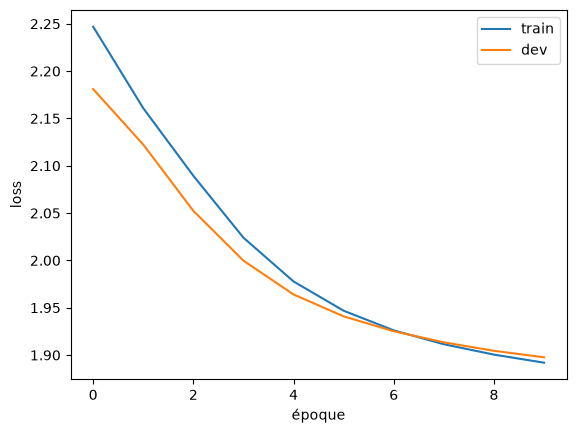

In [36]:
history = model.fit(
    Xtr, Ytr,
    batch_size=32,
    epochs=10,
    validation_data=(Xdev, Ydev),
)

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='dev')
plt.xlabel('époque'); plt.ylabel('loss'); plt.legend()

In [37]:
print('train', model.evaluate(Xtr, Ytr, verbose=0))
print('dev  ', model.evaluate(Xdev, Ydev, verbose=0))

train 1.880427360534668
dev   1.8976494073867798


In [38]:
def generer(n=40, T=1.0):
    for _ in range(n):
        out = []
        context = [0] * block_size
        while True:
            logits = model(np.array([context], dtype=np.int32), training=False)  # (1, vocab_size)
            ix = int(tf.random.categorical(logits / T, num_samples=1)[0, 0])     # tirage selon softmax(logits/T)
            context = context[1:] + [ix]
            if ix == 0:                  # '.' tiré → fin du nom
                break
            out.append(ix)
        print(''.join(itos[i] for i in out))

generer()

saint-et-lauque
peaux
nan
samie
larre-lémigny
mesne
sain-thalène
julins
saint-châssac
colevilles
lamildès
vanthe
channe
haute
cay
saint-bel
drouzard
sous
choosse
cierre-fiches-seraizun
marcheuxin
fosteriau-auben
romlisses
saint-lument
boues
mars
altignon
martine
pagnvillé
brunc
maurenay
bescounet-armon
baillessac
baspantouretay
froy
rac
haussidsà
aux
maziershelmes-le-croves-dwilles
casque


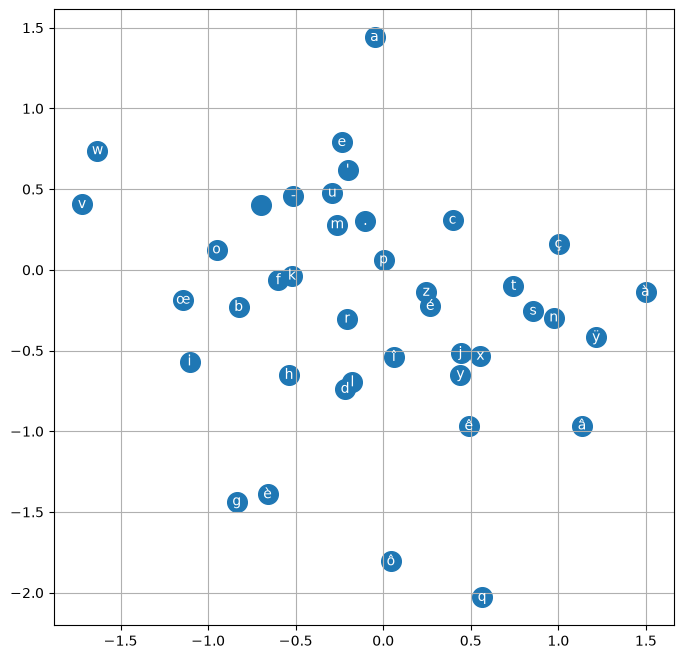

In [39]:
C = model.get_layer('embedding').get_weights()[0]   # (vocab_size, n_embd)

plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0], C[:, 1], s=200)
for i in range(vocab_size):
    plt.text(C[i, 0], C[i, 1], itos[i], ha='center', va='center', color='white')
plt.grid()